**Adverse Drug Reaction (ADR) Data Analysis**

In this notebook we will analyze a dataset of patients, their medications, and reported side effects to identify adverse drug reactions. We will correlate symptoms with drugs, find high-risk medicines, and evaluate possible causes of reactions.

**Import Libraries**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

**Load the dataset**

In [2]:
df = pd.read_csv('/content/real_drug_dataset.csv')
df.head()

,Patient_ID,Age,Gender,Condition,Drug_Name,Dosage_mg,Treatment_Duration_days,Side_Effects,Improvement_Score
0,P0001,56,Male,Infection,Ciprofloxacin,50,9,Nausea,8.5
1,P0002,69,Male,Hypertension,Metoprolol,500,24,Tiredness,8.7
2,P0003,46,Female,Depression,Bupropion,100,25,Dry mouth,5.4
3,P0004,32,Male,Diabetes,Glipizide,850,44,Low blood sugar,6.4
4,P0005,60,Male,Depression,Bupropion,850,35,Anxiety,5.3


**Understand the dataset**

In [3]:
df.shape

(1000, 9)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Patient_ID               1000 non-null   object 
 1   Age                      1000 non-null   int64  
 2   Gender                   1000 non-null   object 
 3   Condition                1000 non-null   object 
 4   Drug_Name                1000 non-null   object 
 5   Dosage_mg                1000 non-null   int64  
 6   Treatment_Duration_days  1000 non-null   int64  
 7   Side_Effects             1000 non-null   object 
 8   Improvement_Score        1000 non-null   float64
dtypes: float64(1), int64(3), object(5)
memory usage: 70.4+ KB


In [5]:
df.describe()

,Age,Dosage_mg,Treatment_Duration_days,Improvement_Score
count,1000.000000,1000.000000,1000.00000,1000.000000
mean,49.857000,352.650000,32.38000,7.015200
std,18.114267,295.419617,15.69809,1.425609
min,18.000000,50.000000,5.00000,2.500000
25%,35.000000,100.000000,19.00000,6.100000
50%,50.000000,250.000000,32.00000,7.000000
75%,66.000000,500.000000,46.00000,8.000000
max,79.000000,850.000000,59.00000,10.000000


**Check for missing values and duplicates**

In [6]:
print("Missing values:")
print(df.isnull().sum())
print()
print("Duplicates:", df.duplicated().sum())

Missing values:
Patient_ID                 0
Age                        0
Gender                     0
Condition                  0
Drug_Name                  0
Dosage_mg                  0
Treatment_Duration_days    0
Side_Effects               0
Improvement_Score          0
dtype: int64

Duplicates: 0


**Check unique values in important columns**

In [7]:
print("Total patients:", len(df))
print("Unique drugs:", df['Drug_Name'].nunique())
print("Unique side effects:", df['Side_Effects'].nunique())
print("Unique conditions:", df['Condition'].nunique())

Total patients: 1000
Unique drugs: 15
Unique side effects: 30
Unique conditions: 5


---
## **1. Most Common Side Effects (Adverse Drug Reactions)**

In [8]:
# count how many times each side effect was reported
side_effect_counts = df['Side_Effects'].value_counts()
side_effect_counts

,count
Side_Effects,
Nausea,167
Dizziness,98
Headache,77
Fatigue,48
Rash,47
Diarrhea,37
Dry mouth,31
Stomach pain,29
Low sugar,27


**Top 10 most common side effects**

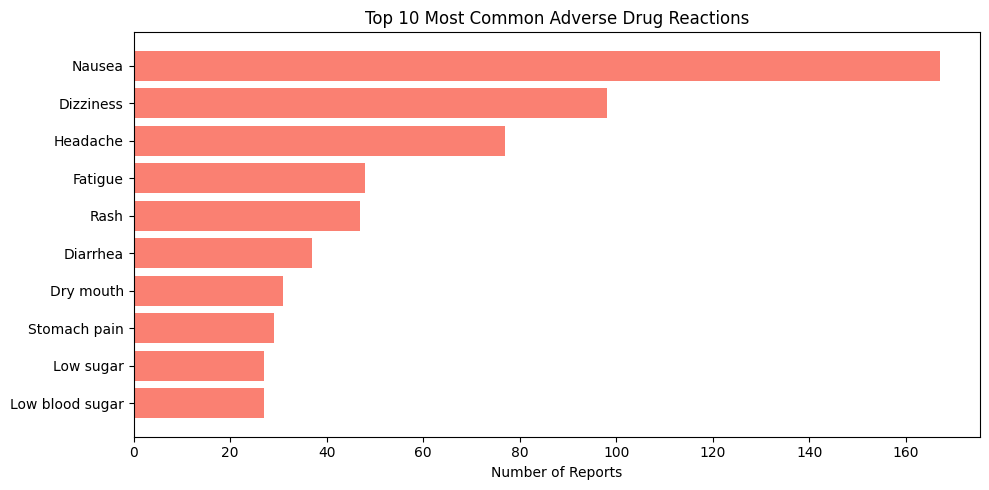

In [9]:
top_10_side_effects = side_effect_counts.head(10)

plt.figure(figsize=(10, 5))
plt.barh(top_10_side_effects.index[::-1], top_10_side_effects.values[::-1], color='salmon')
plt.xlabel('Number of Reports')
plt.title('Top 10 Most Common Adverse Drug Reactions')
plt.tight_layout()
plt.show()

---
## **2. Correlate Symptoms with Drugs**

**Which drug causes which side effects**

In [10]:
# create a cross table showing drug vs side effect counts
drug_side_effect = pd.crosstab(df['Drug_Name'], df['Side_Effects'])
drug_side_effect

Side_Effects,Abdominal pain,Allergy,Anxiety,Back pain,Constipation,Cough,Diarrhea,Dizziness,Drowsiness,Dry mouth,...,Rash,Skin rash,Sleep issues,Slow heartbeat,Stomach pain,Stomach upset,Sweating,Swelling,Tiredness,Weight gain
Drug_Name,,,,,,,,,,,,,,,,,,,,,
Amlodipine,0,0,0,0,0,0,0,27,0,0,...,0,0,0,0,0,0,0,18,0,0
Amoxicillin,0,23,0,0,0,0,19,0,0,0,...,24,0,0,0,0,0,0,0,0,0
Azithromycin,13,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
Bupropion,0,0,24,0,0,0,0,0,0,18,...,0,0,0,0,0,0,0,0,0,0
Ciprofloxacin,0,0,0,0,0,0,0,28,0,0,...,0,0,0,0,0,0,0,0,0,0
Escitalopram,0,0,0,0,0,0,0,0,0,0,...,0,0,21,0,0,0,16,0,0,0
Glipizide,0,0,0,0,0,0,0,0,0,0,...,0,19,0,0,0,0,0,0,0,0
Ibuprofen,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,29,0,0,0,0,0
Insulin Glargine,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,26


**Top side effect for each drug**

In [11]:
# find the most common side effect for each drug
for drug in df['Drug_Name'].unique():
    drug_data = df[df['Drug_Name'] == drug]
    top_effect = drug_data['Side_Effects'].value_counts().index[0]
    count = drug_data['Side_Effects'].value_counts().values[0]
    print(f"{drug} -> {top_effect} ({count} reports)")

Ciprofloxacin -> Nausea (28 reports)
Metoprolol -> Tiredness (20 reports)
Bupropion -> Anxiety (24 reports)
Glipizide -> Low blood sugar (27 reports)
Paracetamol -> Rash (23 reports)
Escitalopram -> Sleep issues (21 reports)
Metformin -> Stomach upset (23 reports)
Amlodipine -> Fatigue (29 reports)
Ibuprofen -> Stomach pain (29 reports)
Tramadol -> Nausea (35 reports)
Azithromycin -> Headache (29 reports)
Sertraline -> Insomnia (22 reports)
Insulin Glargine -> Low sugar (27 reports)
Losartan -> Back pain (25 reports)
Amoxicillin -> Rash (24 reports)


**Side effects reported for each drug (chart)**

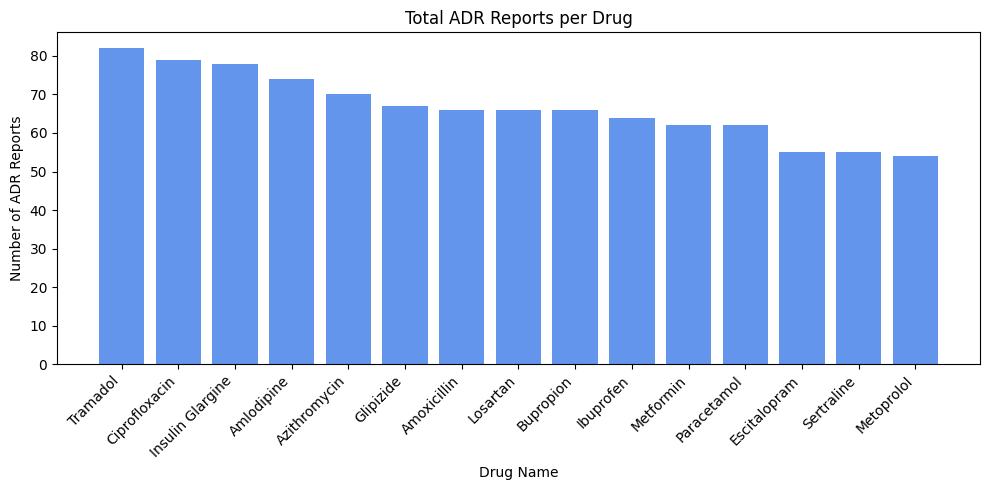

In [12]:
# count total side effect reports per drug
drug_adr_count = df.groupby('Drug_Name')['Side_Effects'].count().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
plt.bar(drug_adr_count.index, drug_adr_count.values, color='cornflowerblue')
plt.xlabel('Drug Name')
plt.ylabel('Number of ADR Reports')
plt.title('Total ADR Reports per Drug')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

---
## **3. Identify High-Risk Medicines**

**Drugs with the lowest improvement scores are high risk**

In [13]:
# average improvement score for each drug
# lower score = drug is not working well = high risk
avg_improvement = df.groupby('Drug_Name')['Improvement_Score'].mean().sort_values()
avg_improvement = avg_improvement.round(2)
print("Average Improvement Score by Drug (lower = higher risk):")
print(avg_improvement)

Average Improvement Score by Drug (lower = higher risk):
Drug_Name
Amlodipine          6.83
Metoprolol          6.88
Tramadol            6.88
Ibuprofen           6.89
Ciprofloxacin       6.90
Azithromycin        7.00
Metformin           7.03
Glipizide           7.04
Sertraline          7.04
Escitalopram        7.07
Paracetamol         7.08
Bupropion           7.11
Losartan            7.13
Amoxicillin         7.17
Insulin Glargine    7.21
Name: Improvement_Score, dtype: float64


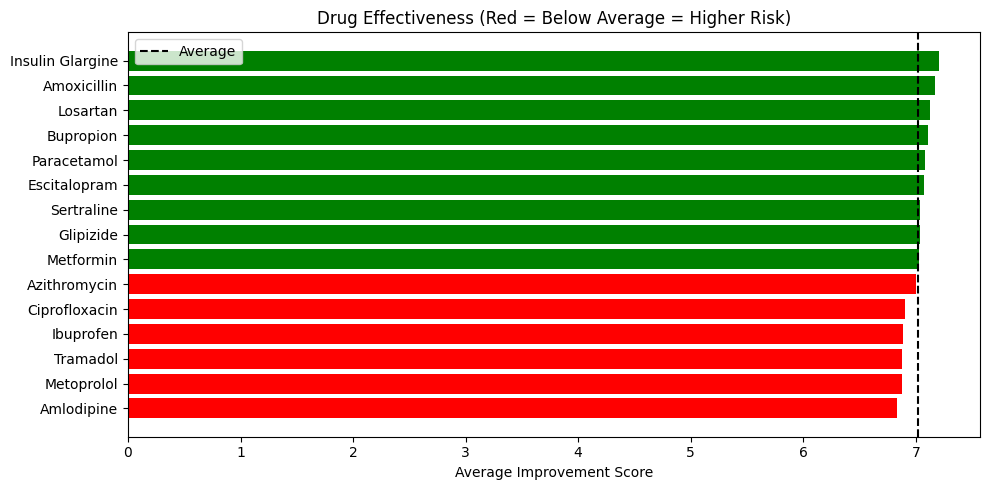

In [14]:
plt.figure(figsize=(10, 5))
colors = ['red' if x < avg_improvement.mean() else 'green' for x in avg_improvement.values]
plt.barh(avg_improvement.index, avg_improvement.values, color=colors)
plt.xlabel('Average Improvement Score')
plt.title('Drug Effectiveness (Red = Below Average = Higher Risk)')
plt.axvline(avg_improvement.mean(), color='black', linestyle='--', label='Average')
plt.legend()
plt.tight_layout()
plt.show()

**Drugs with the most different types of side effects**

In [15]:
# count how many different side effects each drug causes
unique_side_effects = df.groupby('Drug_Name')['Side_Effects'].nunique().sort_values(ascending=False)
print("Number of unique side effects per drug:")
print(unique_side_effects)

Number of unique side effects per drug:
Drug_Name
Amlodipine          3
Amoxicillin         3
Azithromycin        3
Bupropion           3
Ciprofloxacin       3
Escitalopram        3
Glipizide           3
Ibuprofen           3
Insulin Glargine    3
Losartan            3
Metformin           3
Metoprolol          3
Paracetamol         3
Sertraline          3
Tramadol            3
Name: Side_Effects, dtype: int64


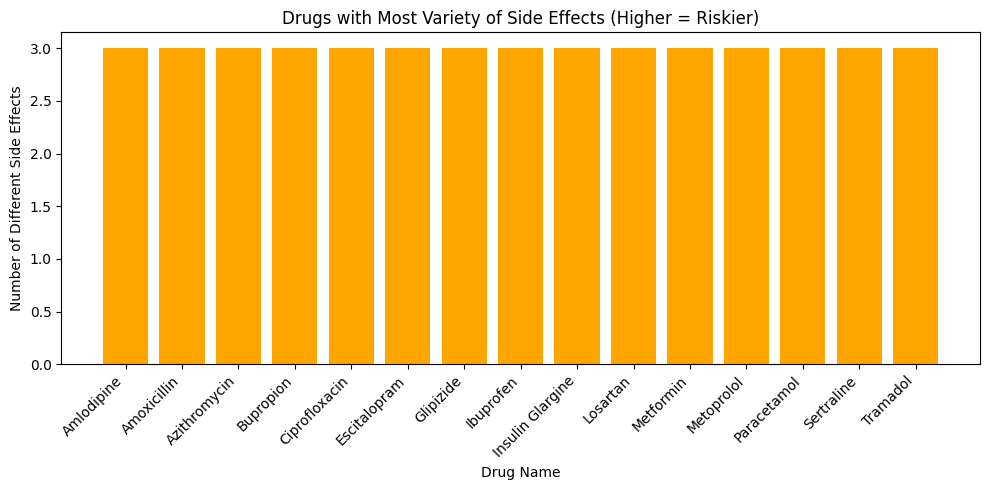

In [16]:
plt.figure(figsize=(10, 5))
plt.bar(unique_side_effects.index, unique_side_effects.values, color='orange')
plt.xlabel('Drug Name')
plt.ylabel('Number of Different Side Effects')
plt.title('Drugs with Most Variety of Side Effects (Higher = Riskier)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**High risk summary - combining low improvement + many side effects**

In [17]:
# combine both metrics into one table
risk_table = pd.DataFrame({
    'Avg_Improvement': avg_improvement,
    'Unique_Side_Effects': unique_side_effects
})

risk_table = risk_table.sort_values('Avg_Improvement')
print("High Risk Drugs (low improvement + many side effects):")
print(risk_table)

High Risk Drugs (low improvement + many side effects):
                  Avg_Improvement  Unique_Side_Effects
Drug_Name                                             
Amlodipine                   6.83                    3
Metoprolol                   6.88                    3
Tramadol                     6.88                    3
Ibuprofen                    6.89                    3
Ciprofloxacin                6.90                    3
Azithromycin                 7.00                    3
Metformin                    7.03                    3
Glipizide                    7.04                    3
Sertraline                   7.04                    3
Escitalopram                 7.07                    3
Paracetamol                  7.08                    3
Bupropion                    7.11                    3
Losartan                     7.13                    3
Amoxicillin                  7.17                    3
Insulin Glargine             7.21                    3


---
## **4. Evaluate Possible Causes of Reactions**

**Does higher dosage cause more side effects?**

In [18]:
# group dosage into low, medium, high
df['Dosage_Level'] = pd.cut(df['Dosage_mg'], bins=3, labels=['Low', 'Medium', 'High'])

# count side effects at each dosage level
dosage_adr = df.groupby('Dosage_Level')['Side_Effects'].count()
print("ADR reports by dosage level:")
print(dosage_adr)

ADR reports by dosage level:
Dosage_Level
Low       599
Medium    198
High      203
Name: Side_Effects, dtype: int64


/tmp/ipykernel_580/534109722.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dosage_adr = df.groupby('Dosage_Level')['Side_Effects'].count()


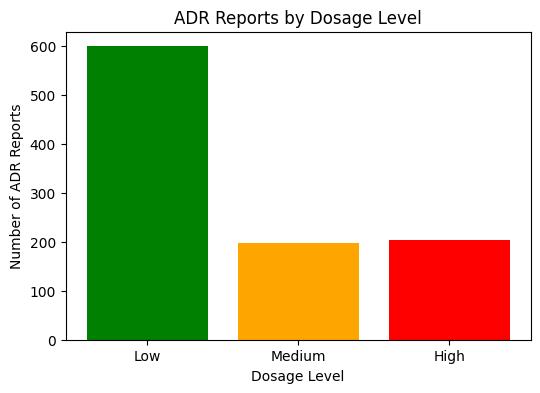

In [19]:
plt.figure(figsize=(6, 4))
plt.bar(dosage_adr.index.astype(str), dosage_adr.values, color=['green', 'orange', 'red'])
plt.xlabel('Dosage Level')
plt.ylabel('Number of ADR Reports')
plt.title('ADR Reports by Dosage Level')
plt.show()

**Does treatment duration affect reactions?**

In [20]:
# group duration into short, medium, long
df['Duration_Level'] = pd.cut(df['Treatment_Duration_days'], bins=3, labels=['Short', 'Medium', 'Long'])

# count side effects at each duration level
duration_adr = df.groupby('Duration_Level')['Side_Effects'].count()
print("ADR reports by treatment duration:")
print(duration_adr)

ADR reports by treatment duration:
Duration_Level
Short     322
Medium    341
Long      337
Name: Side_Effects, dtype: int64


/tmp/ipykernel_580/1929772216.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  duration_adr = df.groupby('Duration_Level')['Side_Effects'].count()


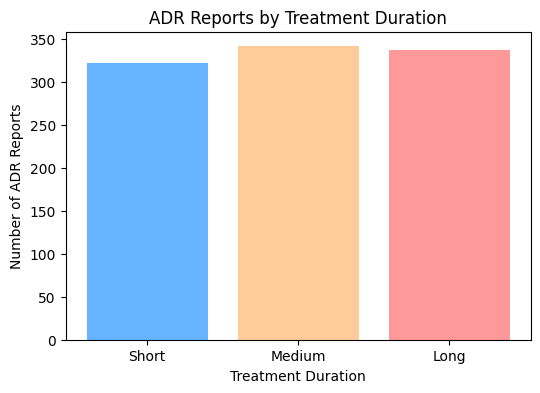

In [21]:
plt.figure(figsize=(6, 4))
plt.bar(duration_adr.index.astype(str), duration_adr.values, color=['#66b3ff', '#ffcc99', '#ff9999'])
plt.xlabel('Treatment Duration')
plt.ylabel('Number of ADR Reports')
plt.title('ADR Reports by Treatment Duration')
plt.show()

**Does age affect adverse reactions?**

In [22]:
# group age into categories
df['Age_Group'] = pd.cut(df['Age'], bins=[0, 30, 50, 80], labels=['Young (18-30)', 'Middle (31-50)', 'Senior (51-80)'])

age_adr = df.groupby('Age_Group')['Side_Effects'].count()
print("ADR reports by age group:")
print(age_adr)

/tmp/ipykernel_580/807216197.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  age_adr = df.groupby('Age_Group')['Side_Effects'].count()


ADR reports by age group:
Age_Group
Young (18-30)     191
Middle (31-50)    323
Senior (51-80)    486
Name: Side_Effects, dtype: int64


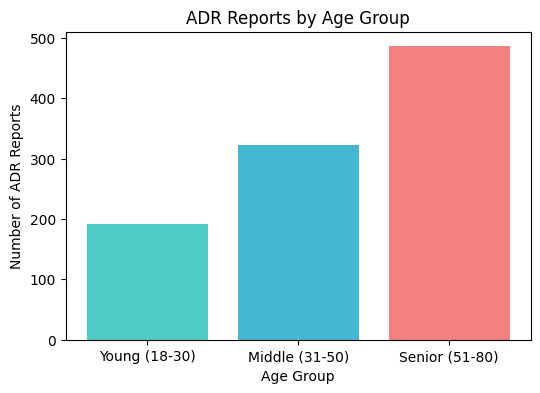

In [23]:
plt.figure(figsize=(6, 4))
plt.bar(age_adr.index.astype(str), age_adr.values, color=['#4ecdc4', '#45b7d1', '#f38181'])
plt.xlabel('Age Group')
plt.ylabel('Number of ADR Reports')
plt.title('ADR Reports by Age Group')
plt.show()

**Average improvement score by age group**

In [24]:
# does age affect how well the drug works?
avg_imp_age = df.groupby('Age_Group')['Improvement_Score'].mean().round(2)
print("Average improvement by age group:")
print(avg_imp_age)

Average improvement by age group:
Age_Group
Young (18-30)     6.85
Middle (31-50)    7.21
Senior (51-80)    6.95
Name: Improvement_Score, dtype: float64


/tmp/ipykernel_580/1613652934.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_imp_age = df.groupby('Age_Group')['Improvement_Score'].mean().round(2)


**Does gender affect adverse reactions?**

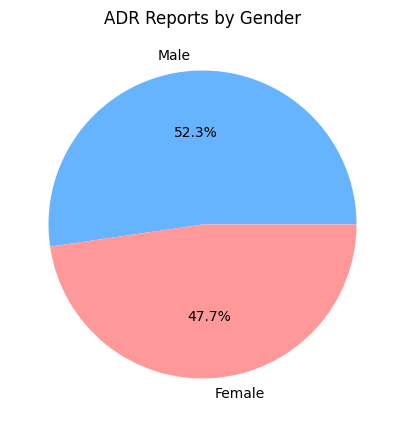

In [25]:
gender_adr = df['Gender'].value_counts()

plt.figure(figsize=(5, 5))
plt.pie(gender_adr.values, labels=gender_adr.index, autopct='%1.1f%%', colors=['#66b3ff', '#ff9999'])
plt.title('ADR Reports by Gender')
plt.show()

**Side effects for each medical condition**

In [26]:
# find the most common side effect for each condition
for condition in df['Condition'].unique():
    cond_data = df[df['Condition'] == condition]
    top_effect = cond_data['Side_Effects'].value_counts().index[0]
    count = cond_data['Side_Effects'].value_counts().values[0]
    print(f"{condition} -> Most common ADR: {top_effect} ({count} reports)")

Infection -> Most common ADR: Nausea (56 reports)
Hypertension -> Most common ADR: Dizziness (47 reports)
Depression -> Most common ADR: Dry mouth (31 reports)
Diabetes -> Most common ADR: Nausea (42 reports)
Pain Relief -> Most common ADR: Nausea (51 reports)


---
## **Summary**

In [27]:
print("SUMMARY")
print()
print("Total patients analyzed:", len(df))
print("Total unique drugs:", df['Drug_Name'].nunique())
print("Total unique side effects:", df['Side_Effects'].nunique())
print("Total conditions treated:", df['Condition'].nunique())
print()
print("Most common side effect:", side_effect_counts.index[0], "(", side_effect_counts.values[0], "reports)")
print("Drug with lowest improvement score:", avg_improvement.index[0], "(", avg_improvement.values[0], ")")
print("Drug with most side effect types:", unique_side_effects.index[0], "(", unique_side_effects.values[0], "types)")
print()
print("Key findings:")
print("- Higher dosage and longer treatment duration can lead to more ADR reports")
print("- Senior patients (51-80) report more adverse reactions compared to younger patients")
print("- Some drugs have many different types of side effects making them higher risk")

SUMMARY

Total patients analyzed: 1000
Total unique drugs: 15
Total unique side effects: 30
Total conditions treated: 5

Most common side effect: Nausea ( 167 reports)
Drug with lowest improvement score: Amlodipine ( 6.83 )
Drug with most side effect types: Amlodipine ( 3 types)

Key findings:
- Higher dosage and longer treatment duration can lead to more ADR reports
- Senior patients (51-80) report more adverse reactions compared to younger patients
- Some drugs have many different types of side effects making them higher risk
